# State-function decomposition

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

import etunc.config as cfg
import etunc.grid as rg
import etunc.temporal as temporal

In [2]:
BIN_VARIABLE = "et"
EDGES = "pooled_all"

TIME_SLICE = slice("2001-01", "2014-12")
TARGET_RES = 1
N_YBINS = 15
N_XBINS = 15


def stem(kind: str) -> str:
    return f"all.{BIN_VARIABLE}_clim.area_weighted.decomp_{kind}.qbin_{EDGES}"


period = temporal.format_time_period(TIME_SLICE)
grid = rg.grid_tag(TARGET_RES)
bins = cfg.bins_tag(N_YBINS, N_XBINS)

out_dir = cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", period, bins)

In [3]:
fout = out_dir / f"{stem('vs_obs')}.{bins}.{grid}.{period}.nc"

vs_obs = xr.open_dataset(fout)
vs_obs_df = pd.read_csv(fout.with_suffix(".csv"))

In [4]:
d = "obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2"
o = "WECANN-GIMMS_LAI4g-GPCPv2.3-CERESed4.2"

vs_obs.E_rr.sel(dataset=d, obs_reference=o).values

array(44.60011703)

In [5]:
vs_obs_df

,dataset,obs_reference,E_rr,E_rm,E_mr,E_mm,FUNCTION,STATE,INTERACTION,E_m,...,family,source,et_product,lai_product,pr_product,rn_product,ref_et_product,ref_lai_product,ref_pr_product,ref_rn_product
0,obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,41.495924,41.495924,41.495924,41.495924,0.000000,0.000000,0.000000,41.495924,...,obs,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
1,obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,DOLCE-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,40.598502,41.424716,40.661965,41.490065,0.826214,0.063463,0.001887,41.495924,...,obs,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2,DOLCE,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
2,obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,FLUXCOM-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,52.961094,41.675429,52.714348,41.489262,-11.285665,-0.246746,0.060580,41.495924,...,obs,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2,FLUXCOM,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
3,obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,GLEAMv3.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,46.486241,41.675429,46.247071,41.489262,-4.810812,-0.239170,0.053003,41.495924,...,obs,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2,GLEAMv3.3a,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
4,obs.CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,MOD16A2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,42.059132,41.675429,41.835166,41.489262,-0.383703,-0.223966,0.037800,41.495924,...,obs,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2,MOD16A2,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2374,trendy_s3_pooled,PMLv2.2c-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,44.821018,42.456112,49.662983,44.598940,-2.364907,4.841965,-2.699137,45.397953,...,trendy_s3,pooled,none,none,none,none,PMLv2.2c,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
2375,trendy_s3_pooled,GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,45.774812,42.456112,49.843328,44.598940,-3.318701,4.068516,-1.925687,45.397953,...,trendy_s3,pooled,none,none,none,none,GLEAMv4.3a,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
2376,trendy_s3_pooled,GLEAMv4.3b-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,50.638923,42.561457,54.520939,44.616361,-8.077466,3.882016,-1.827112,45.397953,...,trendy_s3,pooled,none,none,none,none,GLEAMv4.3b,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
2377,trendy_s3_pooled,SiTHv2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,48.290334,42.456112,53.828985,44.598940,-5.834223,5.538651,-3.395823,45.397953,...,trendy_s3,pooled,none,none,none,none,SiTHv2,GIMMS_LAI4g,GPCPv2.3,CERESed4.2


In [6]:
vs_obs_df.loc[vs_obs_df["dataset"] == "cmip_pooled"]

,dataset,obs_reference,E_rr,E_rm,E_mr,E_mm,FUNCTION,STATE,INTERACTION,E_m,...,family,source,et_product,lai_product,pr_product,rn_product,ref_et_product,ref_lai_product,ref_pr_product,ref_rn_product
754,cmip_pooled,CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,41.495924,48.623853,44.110828,49.727966,7.127929,2.614904,-1.510791,50.181075,...,cmip,pooled,none,none,none,none,CLASS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
755,cmip_pooled,DOLCE-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,40.598502,48.542533,43.577836,49.715222,7.944031,2.979334,-1.806646,50.181075,...,cmip,pooled,none,none,none,none,DOLCE,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
756,cmip_pooled,FLUXCOM-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,52.967947,48.803664,57.052613,49.773130,-4.164284,4.084666,-3.115200,50.181075,...,cmip,pooled,none,none,none,none,FLUXCOM,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
757,cmip_pooled,GLEAMv3.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,46.487459,48.803664,49.171590,49.773130,2.316205,2.684131,-1.714665,50.181075,...,cmip,pooled,none,none,none,none,GLEAMv3.3a,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
758,cmip_pooled,MOD16A2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,42.059649,48.803664,45.653159,49.773130,6.744015,3.593510,-2.624043,50.181075,...,cmip,pooled,none,none,none,none,MOD16A2,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
759,cmip_pooled,MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,42.062846,48.790872,45.679235,49.719826,6.728027,3.616389,-2.687436,50.181075,...,cmip,pooled,none,none,none,none,MODIS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
760,cmip_pooled,WECANN-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,44.604621,48.982084,46.833993,49.722231,4.377464,2.229372,-1.489226,50.181075,...,cmip,pooled,none,none,none,none,WECANN,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
761,cmip_pooled,PMLv2.2a_MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,44.824647,48.803664,47.235870,49.773130,3.979017,2.411224,-1.441757,50.181075,...,cmip,pooled,none,none,none,none,PMLv2.2a_MODIS,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
762,cmip_pooled,PMLv2.2c-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,44.821018,48.803664,47.232665,49.773130,3.982645,2.411646,-1.442180,50.181075,...,cmip,pooled,none,none,none,none,PMLv2.2c,GIMMS_LAI4g,GPCPv2.3,CERESed4.2
763,cmip_pooled,GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2,45.774812,48.803664,47.895952,49.773130,3.028851,2.121140,-1.151674,50.181075,...,cmip,pooled,none,none,none,none,GLEAMv4.3a,GIMMS_LAI4g,GPCPv2.3,CERESed4.2


## Counterfactual means by family

One box per family and counterfactual mean (E_mm, E_rm, E_mr), across the family's members, each against `obs_pooled` (the `<family>_pooled` rows are left out). The obs box is E_rr of each obs source against itself: with a complete support this is the source's full-domain ET, so the box is the spread across the ET products. The dashed line is the ET of `obs_pooled`, the reference of every family's boxes. Whiskers: 1.5 IQR; a family with one member (era5) is drawn as markers.

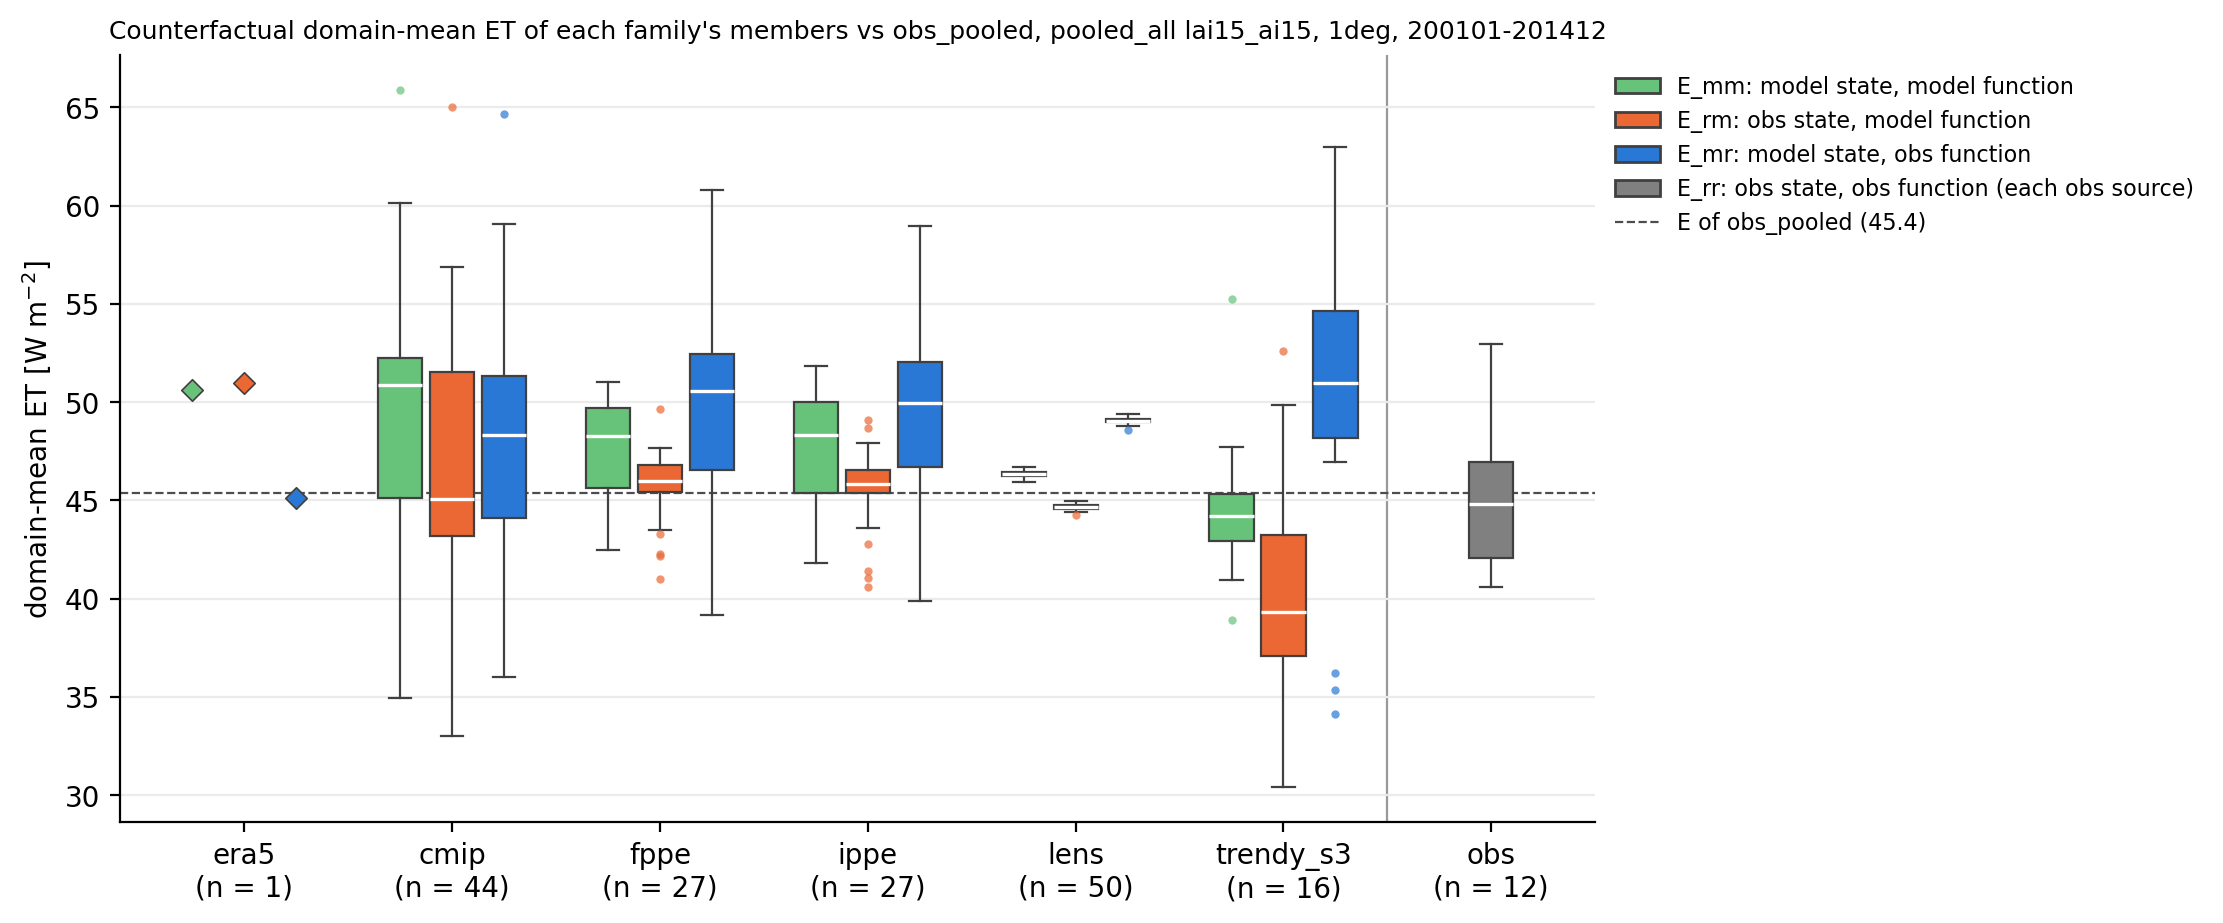

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FAMILIES = ["era5", "cmip", "fppe", "ippe", "lens", "trendy_s3"]
MEANS = ["E_mm", "E_rm", "E_mr"]
COLORS = {"E_rr": "#808080", "E_rm": "#eb6834", "E_mr": "#2a78d6", "E_mm": "#66c379"}
LABELS = {
    "E_mm": "E_mm: model state, model function",
    "E_rm": "E_rm: obs state, model function",
    "E_mr": "E_mr: model state, obs function",
    "E_rr": "E_rr: obs state, obs function (each obs source)",
}

# Members of every family against obs_pooled, without the <family>_pooled rows
ref = vs_obs.sel(obs_reference="obs_pooled")
members = ref.isel(dataset=np.flatnonzero((ref["source"] != "pooled").values))

# Obs: E_rr of each obs source against itself (its own reference)
obs_idx = np.flatnonzero((vs_obs["family"] == "obs").values)
obs_self = np.array([float(vs_obs["E_rr"].isel(dataset=i).sel(obs_reference=str(vs_obs["source"].values[i])))
                     for i in obs_idx])


def draw_box(ax, values, x, color, width):
    """A box and whiskers of `values` at `x`; a single value as a marker."""
    if values.size == 1:
        ax.scatter([x], values, marker="D", s=30, color=color, edgecolor="0.25", linewidth=0.6, zorder=3)
        return
    ax.boxplot(values, positions=[x], widths=width, patch_artist=True, zorder=2,
               boxprops=dict(facecolor=color, edgecolor="0.25", linewidth=0.8),
               medianprops=dict(color="white", linewidth=1.2),
               whiskerprops=dict(color="0.25", linewidth=0.8), capprops=dict(color="0.25", linewidth=0.8),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=color, markeredgecolor="none", alpha=0.7))


width = 0.25
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained", dpi=200)
ticks, ticklabels = [], []
for i, fam in enumerate(FAMILIES):
    sel = members.isel(dataset=np.flatnonzero((members["family"] == fam).values))
    for k, q in enumerate(MEANS):
        draw_box(ax, sel[q].values, i + (k - 1) * width, COLORS[q], 0.85 * width)
    ticks.append(i)
    ticklabels.append(f"{fam}\n(n = {sel.sizes['dataset']})")

# Obs, set apart by a line
x_obs = len(FAMILIES)
ax.axvline(x_obs - 0.5, color="0.6", linewidth=0.8, zorder=1)
draw_box(ax, obs_self, x_obs, COLORS["E_rr"], 0.85 * width)
ticks.append(x_obs)
ticklabels.append(f"obs\n(n = {obs_self.size})")

# The reference of every family's boxes
E_pool = float(ref["E_r"].isel(dataset=0))
ax.axhline(E_pool, color="0.3", linestyle="--", linewidth=0.8, zorder=1)

ax.set_xticks(ticks, ticklabels)
ax.set_xlim(-0.6, x_obs + 0.5)
ax.set_ylabel("domain-mean ET [W m$^{-2}$]")
ax.grid(axis="y", color="0.92", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
handles = [Patch(facecolor=COLORS[q], edgecolor="0.25", label=LABELS[q]) for q in MEANS + ["E_rr"]]
handles.append(Line2D([], [], color="0.3", linestyle="--", linewidth=0.8, label=f"E of obs_pooled ({E_pool:.1f})"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
ax.set_title(f"Counterfactual domain-mean ET of each family's members vs obs_pooled, {EDGES} {bins}, {grid}, {period}",
             fontsize=9)
plt.show()